In [18]:
import numpy as np
import pandas as pd
from matplotlib import pyplot
import os
import sys

if '../../lib/' not in sys.path:
    sys.path.append('../../lib/')
import plot_util as putil

In [19]:
gas_names = ['H-alpha', 'HI', 'CO', 'dust']
#models = ['prior', 'cov']
models = ['prior',]
stypes = ['unas', 'assoc']
def norm_gas(df, cols=gas_names, norm=None, norm_component=None):
    if norm is None:
        norm = {}
        for col in cols:
            if norm_component is None:
                norm[col] = np.max(df[col])
            else:
                norm[col] = df[col].loc[norm_component]
    for col in cols:
        df[col] /= norm[col]
    return norm, df

In [20]:
script_fn = 'fermi_multiclass/notebooks/star_forming/plot_gas_corrs.ipynb'
fig_meta = {'Author': 'Dmitry Malyshev', 'Subject': script_fn}
plots_folder = '../../plots/gas_correlations/'
if not os.path.isdir(plots_folder):
    os.makedirs(plots_folder)
    
save_plots = 1
save_png = 1
pars_dict={'legend.fontsize': 12}
pars_dict['top'] = 0.9
putil.setup_figure_pars(pars_dict)


0

In [22]:
folder = '../../results/gas_correlations/'
res_dict = {}
llat = False
hlat = 0
bmask = 15.
if bmask > 15:
    norm_component = 'msp+'
else:
    norm_component = None

if llat:
    smask_str = '_b<%ideg' % bmask
    title_str = r'Low latitudes (|b| < $%i^\circ$)' % bmask
elif hlat:
    smask_str = '_b>%ideg' % bmask
    title_str = r'High latitudes (|b| > $%i^\circ$)' % bmask
else:
    smask_str = ''
    title_str = 'All sky'
    if len(models) == 1 and models[0] == 'prior':
        title_str += ', prior shift classification'
    
for model in models:
    res_dict[model] = {}
    afn = '%s%s_shift_model_gas_correlations_assoc%s.csv' % (folder, model, smask_str)
    ufn = '%s%s_shift_model_gas_correlations_unas%s.csv' % (folder, model, smask_str)
        
    df = pd.read_csv(afn, index_col=1)
    norm, df = norm_gas(df, norm=None, norm_component=norm_component)
    res_dict[model]['assoc'] = df
    
    df = pd.read_csv(ufn, index_col=1)
    norm, df = norm_gas(df, norm=norm)
    res_dict[model]['unas'] = df


In [23]:
res_dict['prior']['assoc']

,Unnamed: 0,H-alpha,HI,CO,dust,sources
Class,,,,,,
fsrq+,1,0.063850,0.046835,0.002021,0.016408,350
bll+,2,0.051621,0.039942,0.001390,0.012674,1009
psr+,3,1.000000,1.000000,1.000000,1.000000,146
msp+,4,0.180243,0.139601,0.026958,0.085633,230


In [24]:
res_dict['prior']['unas']

,Unnamed: 0,H-alpha,HI,CO,dust,sources
Class,,,,,,
fsrq+,1,0.366804,0.321329,0.197296,0.253566,508.808557
bll+,2,0.175909,0.115829,0.024925,0.061898,1742.912634
psr+,3,1.139467,1.143595,1.211966,1.379081,93.967563
msp+,4,0.647632,0.463757,0.269506,0.422267,883.920872
Gauss,Gauss,0.661007,0.449332,0.192099,0.339588,1535.390374


unas prior
unas prior
unas prior
unas prior
unas prior
assoc prior
assoc prior
assoc prior
assoc prior
save figure to file: ../../plots/gas_correlations//gas_correlations.pdf


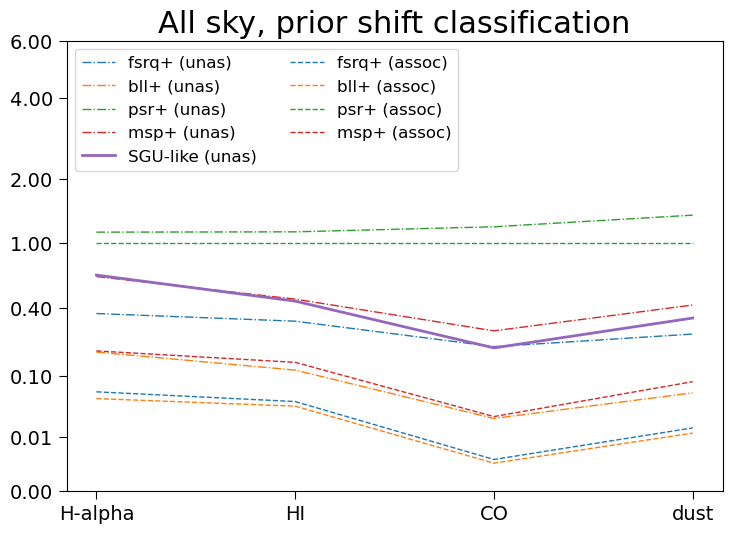

In [29]:
ncol = len(models) + 1
clrs = {}
lss = {'assoc_prior': '--', 'unas_cov':':', 'unas_prior':'-.'}
#pyplot.figure()
fig, ax = pyplot.subplots(1, 1)
#ax = axs[0]
for i, stype in enumerate(stypes):
    for j, model in enumerate(models):
        if i + j < 2:
            df = res_dict[model][stype]
            for ind in df.index:
                color = clrs.get(ind)
                print(stype, model)
                ls = lss.get('%s_%s' % (stype, model), ':')
                if ind == 'Gauss':
                    ls = '-'
                    lw = 2
                else:
                    lw = 1
                    
                if ind == 'Gauss':
                    cname = 'SGU-like'
                else:
                    cname = ind
                label='%s (%s)' % (cname, stype[:7])
                if stype == 'unas' and len(models) > 1:
                    label += ' %s' % model
                ln = pyplot.plot(df[gas_names].loc[ind], lw=lw, color=color, ls=ls, label=label)[0]
                clrs[ind] = ln.get_color()
pyplot.legend(ncol=ncol, loc='upper left')
ymin = 0.
ymax = 6.
pyplot.ylim(ymin, ymax)
power = 1/3.
ipower = 1/power
forward = lambda x:x**power
inverse = lambda x:x**ipower
ax.set_yscale('function', functions=(forward, inverse))
#yticks = np.around(np.linspace(ymin, ymax**power, 5)**ipower, decimals=1)
yticks = [0., 0.01, 0.1, 0.4, 1., 2., 4., 6.]
pyplot.yticks(yticks)
pyplot.title(title_str)

if save_plots:
    fn = '%s/gas_correlations%s.pdf' % (plots_folder, smask_str)

    print('save figure to file: %s' % (fn))
    pyplot.savefig(fn, metadata=fig_meta)
    if save_png:
        fn = fn.replace('.pdf', '.png')
        pyplot.savefig(fn, metadata=fig_meta)


In [26]:
ind

'msp+'